# Ticket price data: what it shows so far

This notebook covers both datasets in this folder:

1. **US fares (Expedia, 2022):** daily quotes for 235 routes. This is the data behind the backtest and the model.
2. **Germany (live scraper):** the Eurostat fare index since 1996, plus Ryanair and Google Flights fares. So far there are only snapshots from one day.

It only reads data and writes no files, so it's safe to re-run.

### How the test period is handled

The fare-pattern sections (1.2 to 1.8) use **training data only**, the same data the rules and models could learn from. Sections 1.9 and 1.10 then show what happened in the test period.

The one-time final test ran on 2026-11-03 at 17:34. These charts can't affect that result, but **anything you choose after seeing them no longer has a clean test**. A fair check of a new idea needs new data, not a re-run on this period.

## What the data shows

Figures are from the run on 2026-11-03. Each one is worked out in the section named beside it.

**US fares, 2022**

- **Buying the day before is expensive.** It cost $105 more per trip than buying 30 days out in the test period, and was dearer on 94% of trips (1.9).
- **Fares rise in steps, not smoothly.** 39% to 74% of trips get dearer when moving to 20, 13, 5 and 1 days out, against about 20% on an ordinary day (1.3).
- **No fixed waiting rule is reliable.** In training, waiting until 14 days saved $9.55. In the test period it cost $17.96, with 61% of trips dearer (1.10). Waiting paid when the market was falling and lost when it was rising, so market direction looks like the main driver, though this data covers only one season and can't prove it.
- **Route-specific timing is mostly noise.** Only 13% of routes had the same best lead in both halves of training (1.6), and the per-route rule lost $24.39 per trip in the final test (1.9).
- **The models' edge is real but fragile.** LightGBM saved $6.62 per trip (95% CI $4.32 to $8.86), about a quarter of the $25.96 perfect hindsight could save. If each purchase goes through a day late, it loses $11.29 instead (1.9).
- **Departure day matters at every lead.** Tuesdays and Wednesdays run about 13% below a route's median when booked 31 to 60 days out, while Sundays run 11% above (1.8).

**Points to check in the pipeline**

- `best_fixed_lead` picks by mean ratio but is scored in dollars, and on training trips the two disagree: 30 days against 14 (1.4).
- JetBlue is the cheapest airline on 23.5% of training quotes, and none of its fares are flagged as basic economy, so some may not be like-for-like (1.8).
- `seats_remaining` mostly tops out at 7 on American, JetBlue and Alaska, and at 9 on United and Delta, so its raw value partly identifies the airline (1.8).

**Germany**

- **Fares are up and more volatile.** The index rose 28% from 2019 to 2025, and the typical one-month move went from 1.7% in 2015-2019 to 7.6% since 2024 (2.1). Domestic fares moved ahead of international in 2025 (2.2).
- **There's no fare history yet.** With one day of snapshots, lead time can't be separated from departure date. Ryanair's median fare is €25 in the cheapest week and €90 in Christmas week, which is the calendar at work rather than lead time (2.4).

**Limits:** the US data covers about five and a half months of 2022, and the test period is only 39 departure dates, from late August to early October. These findings may not hold in other seasons or years.

In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import FuncFormatter

# Don't import ticket_prices.curves here: it switches matplotlib to a backend with no inline plots.
from ticket_prices.backtest import Config, best_fixed_lead, split_trips, trip_curves
from ticket_prices.prepare import EXCLUDED_AIRLINES

SERIES_PATH = Path("data/processed/daily_cheapest.parquet")
ITINERARIES_PATH = Path("data/processed/itineraries.parquet")
REPORTS = Path("reports")
GERMANY = Path("germany-flight-fares/data")

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SEQUENTIAL = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.constrained_layout.use": True,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": AXIS, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titlepad": 10,
    "lines.linewidth": 2, "legend.frameon": False,
})
DOLLARS = FuncFormatter(lambda value, _: f"{'-' if value < 0 else ''}${abs(value):,.0f}")
EUROS = FuncFormatter(lambda value, _: f"€{value:,.0f}")


def lead_axis(ax, start=30, end=1):
    """Time runs left to right, towards departure."""
    ax.set_xlim(start + .5, end - .5)
    ax.set_xticks([30, 25, 20, 15, 10, 5, 1])
    ax.set_xlabel("Days before departure")


cfg = Config()
setup = json.loads((REPORTS / "backtest_setup.json").read_text())
SPLIT = pd.Timestamp(setup["split_date"])

series = pd.read_parquet(SERIES_PATH)
for column in ("flightDate", "searchDate"):
    series[column] = pd.to_datetime(series[column])

curves = trip_curves(series, cfg)
train, test = split_trips(curves, SPLIT, cfg)
train_quotes = series[series["searchDate"] < SPLIT]
buy = train.bfill(axis=1)  # a day with no quote slips to the next quoted day, as in the backtest
flight_dates = train.index.get_level_values("flightDate")

print(f"Split date: {SPLIT.date()}")
print(f"Training: {len(train):,} trips, {len(train_quotes):,} quotes, departures {flight_dates.min().date()} to {flight_dates.max().date()}")

Split date: 2022-07-28
Training: 13,199 trips, 1,236,244 quotes, departures 2022-05-18 to 2022-07-28


---
# Part 1: US fares

## 1.1 What the data covers

A **quote** here is the cheapest comparable fare for one route, departure date and search date. Basic economy, premium cabins, Spirit and Frontier are excluded. A **trip** is a route and departure date, with buying allowed from 30 days out to 1 day out.

The chart shows how many route and departure combinations were quoted each search day. Pale or blank columns are days when collection was partial or missed. Those days don't reach the full 60-day horizon, so anything using leads beyond about 45 days rests on less data.

,
Raw itinerary rows,"82,138,753"
Distinct flights,"5,999,739"
Routes,235
Search dates,2022-04-16 to 2022-10-05
Departure dates,2022-04-17 to 2022-11-19
Quotes in the daily series,"1,985,519"
Search days with no data,"2022-05-15, 2022-05-16"
Usable trips (train / test),"13,199 / 9,040"


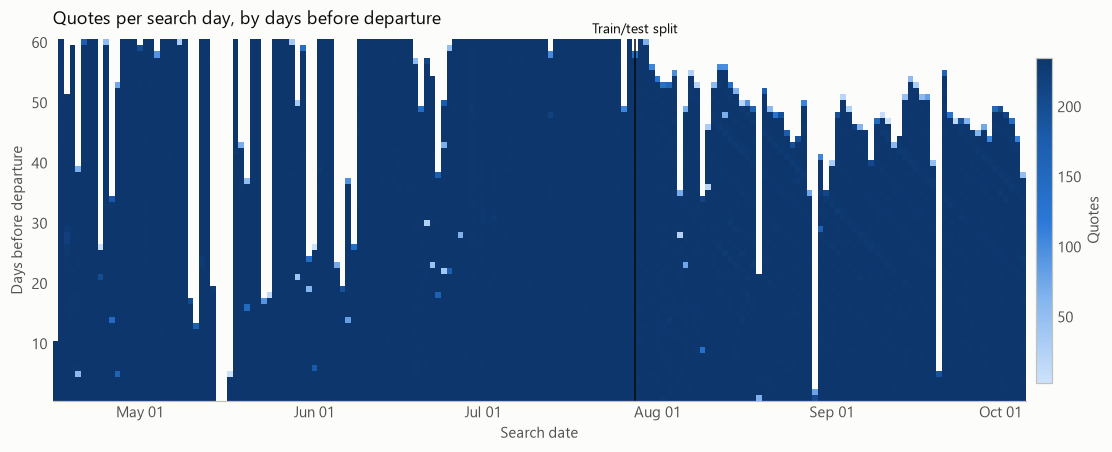

Search days under the 60-day horizon: 102 of 171


In [2]:
checks = json.loads((REPORTS / "data_checks.json").read_text())
display(pd.Series({
    "Raw itinerary rows": f"{checks['rows']:,}",
    "Distinct flights": f"{checks['distinct_flights']:,}",
    "Routes": checks["routes"],
    "Search dates": " to ".join(checks["search_dates"]),
    "Departure dates": " to ".join(checks["flight_dates"]),
    "Quotes in the daily series": f"{len(series):,}",
    "Search days with no data": ", ".join(checks["missing_search_days"]),
    "Usable trips (train / test)": f"{len(train):,} / {len(test):,}",
}, name="").to_frame())

coverage = (
    series.groupby(["days_to_departure", "searchDate"]).size().unstack()
    .reindex(columns=pd.date_range(series["searchDate"].min(), series["searchDate"].max()))
)
fig, ax = plt.subplots(figsize=(10, 4))
x0, x1 = mdates.date2num(coverage.columns[0]), mdates.date2num(coverage.columns[-1])
image = ax.imshow(np.ma.masked_invalid(coverage.to_numpy()), aspect="auto", origin="lower", cmap=SEQUENTIAL,
                  extent=[x0 - .5, x1 + .5, coverage.index[0] - .5, coverage.index[-1] + .5], interpolation="nearest")
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.axvline(mdates.date2num(SPLIT), color=INK, linewidth=1)
ax.annotate("Train/test split", (mdates.date2num(SPLIT), coverage.index[-1] + .5), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, annotation_clip=False)
ax.grid(False)
ax.set(title="Quotes per search day, by days before departure", xlabel="Search date", ylabel="Days before departure")
fig.colorbar(image, ax=ax, label="Quotes", pad=0.01, shrink=0.9)
plt.show()

daily_counts = series.groupby("searchDate").agg(quotes=("price", "size"), furthest_lead=("days_to_departure", "max"))
print(f"Search days under the 60-day horizon: {(daily_counts['furthest_lead'] < 60).sum()} of {len(daily_counts)}")

## 1.2 The market moved during the training period

Fares rose until about the start of June and then fell through late July. That matters for reading everything below: a traveller who waits is also moving through the market, so a saving from waiting may come partly from this drift rather than from how close the flight is. Section 1.10 tests this.

Search days that don't reach 30 days out are left out, so the mix of leads stays comparable.

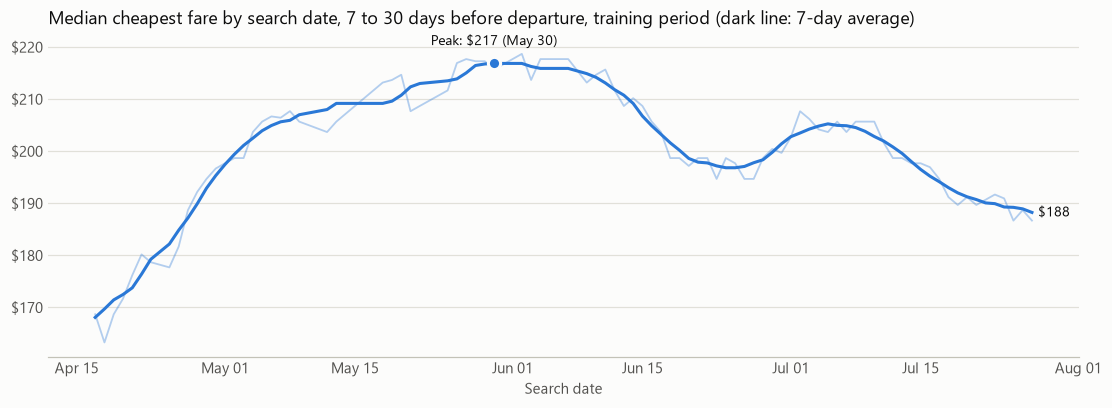

Start: $168. Peak: $217 on 2022-05-30. End: $188 (-13% from peak)


In [3]:
def market_level(quotes):
    """Median fare per search day, 7 to 30 days out, on days that reach 30 days out."""
    reach = quotes.groupby("searchDate")["days_to_departure"].transform("max")
    return quotes[quotes["days_to_departure"].between(7, 30) & (reach >= 30)].groupby("searchDate")["price"].median()


market = market_level(train_quotes)
smooth = market.rolling(7, center=True, min_periods=4).mean()
peak = smooth.idxmax()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(market.index, market, color=BLUE, linewidth=1.2, alpha=.35)
ax.plot(smooth.index, smooth, color=BLUE)
ax.plot(peak, smooth[peak], "o", ms=8, color=BLUE, mec=SURFACE, mew=2)
ax.annotate(f"Peak: ${smooth[peak]:.0f} ({peak:%b %d})", (peak, smooth[peak]), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9)
ax.annotate(f"${smooth.dropna().iloc[-1]:.0f}", (smooth.dropna().index[-1], smooth.dropna().iloc[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.yaxis.set_major_formatter(DOLLARS)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set(title="Median cheapest fare by search date, 7 to 30 days before departure, training period (dark line: 7-day average)", xlabel="Search date")
plt.show()
print(f"Start: ${smooth.dropna().iloc[0]:.0f}. Peak: ${smooth[peak]:.0f} on {peak.date()}. End: ${smooth.dropna().iloc[-1]:.0f} ({100 * (smooth.dropna().iloc[-1] / smooth[peak] - 1):+.0f}% from peak)")

## 1.3 Fares rise in steps

The average fare is nearly flat until 14 days out. It then rises in steps, not in a smooth curve. The lower chart shows why: on most days about one trip in five gets dearer, but on a few specific days most do.

The 21-to-20 and 14-to-13 steps sit right where advance-purchase rules commonly end, which is a plausible cause, though this data can't confirm it.

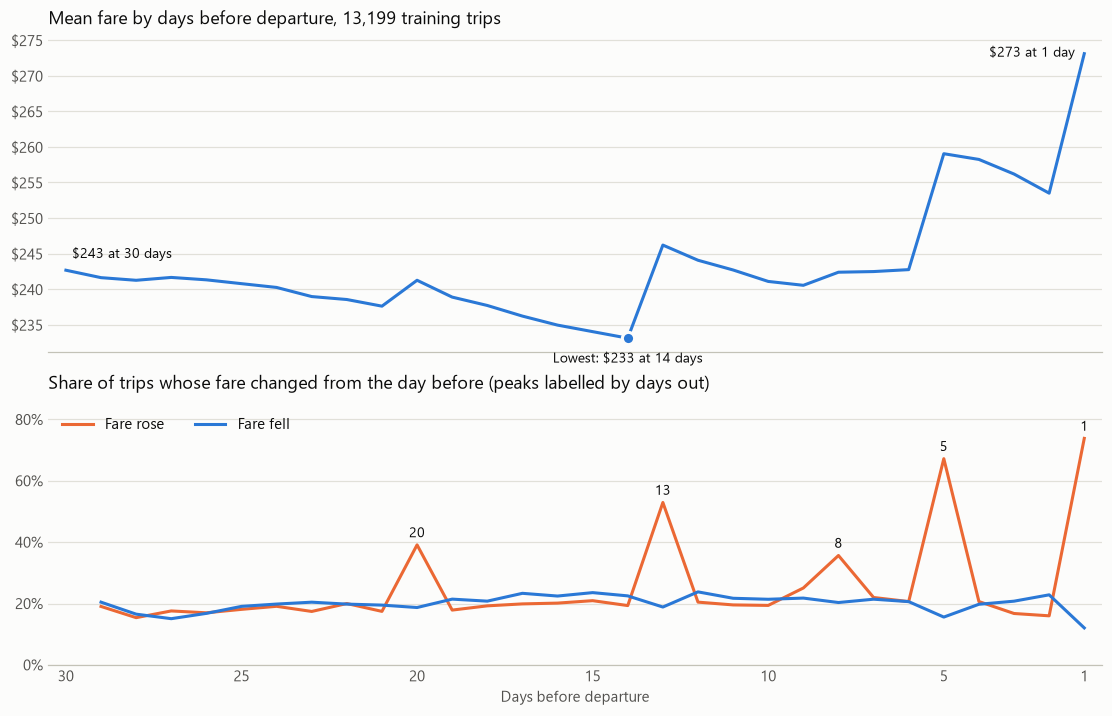

,share_rising,share_falling,mean_change_pct
days_to_departure,,,
20,0.391,0.187,3.598
13,0.529,0.188,8.866
8,0.356,0.203,1.557
5,0.672,0.156,9.395
1,0.738,0.120,11.279


Median curve matches reports/booking_curve.csv: True


In [4]:
known = train.ffill(axis=1)
day_change = known.diff(axis=1)
steps = pd.DataFrame({
    "mean_fare": buy.mean(),
    "median_fare": buy.median(),
    "share_rising": (day_change > 0).sum() / day_change.notna().sum(),
    "share_falling": (day_change < 0).sum() / day_change.notna().sum(),
    "mean_change_pct": 100 * known.pct_change(axis=1, fill_method=None).mean(),
})
step_leads = steps["share_rising"].nlargest(5).index.sort_values(ascending=False)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, height_ratios=[1.2, 1])
top.plot(steps.index, steps["mean_fare"], color=BLUE)
top.yaxis.set_major_formatter(DOLLARS)
top.set_title(f"Mean fare by days before departure, {len(train):,} training trips")
lowest = steps["mean_fare"].idxmin()
top.plot(lowest, steps.loc[lowest, "mean_fare"], "o", ms=8, color=BLUE, mec=SURFACE, mew=2)
top.annotate(f"Lowest: ${steps.loc[lowest, 'mean_fare']:.0f} at {lowest} days", (lowest, steps.loc[lowest, "mean_fare"]),
             xytext=(0, -16), textcoords="offset points", ha="center", fontsize=9)
top.annotate(f"${steps.loc[1, 'mean_fare']:.0f} at 1 day", (1, steps.loc[1, "mean_fare"]),
             xytext=(-6, -2), textcoords="offset points", ha="right", fontsize=9)
top.annotate(f"${steps.loc[30, 'mean_fare']:.0f} at 30 days", (30, steps.loc[30, "mean_fare"]),
             xytext=(4, 8), textcoords="offset points", fontsize=9)

bottom.plot(steps.index, 100 * steps["share_rising"], color=ORANGE, label="Fare rose")
bottom.plot(steps.index, 100 * steps["share_falling"], color=BLUE, label="Fare fell")
for lead in step_leads:
    bottom.annotate(f"{lead}", (lead, 100 * steps.loc[lead, "share_rising"]), xytext=(0, 5), textcoords="offset points",
                    ha="center", fontsize=9)
bottom.set_ylim(0, 85)
bottom.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0f}%"))
bottom.set_title("Share of trips whose fare changed from the day before (peaks labelled by days out)")
bottom.legend(loc="upper left", ncols=2)
lead_axis(bottom)
plt.show()

display(steps.loc[step_leads, ["share_rising", "share_falling", "mean_change_pct"]].round(3))

# Check against the saved report: same trips and same definition should give the same curve.
saved = pd.read_csv(REPORTS / "booking_curve.csv", index_col=0)
mine = train.div(train[cfg.start_lead], axis=0).median()
print("Median curve matches reports/booking_curve.csv:", bool(np.allclose(saved["median"].reindex(mine.index), mine)))

## 1.4 The "best fixed lead" depends on how you average

`best_fixed_lead` picks the lead with the lowest **mean ratio to the first-day fare**, and that picks 30 days. The backtest is scored in **dollars**, and mean dollars are lowest at 14 days.

They disagree because a mean of ratios gives extra weight to trips that happened to be cheap on day 30, since those ratios can get very large. A $60 fare doubling counts the same as a $400 fare doubling.

So the baseline rule chooses by a different measure from the one it's scored on. **But 14 days isn't good advice either:** the table shows waiting paid only for departures from mid-June on, when the market was falling (section 1.2). Section 1.10 shows what it did in the test period.

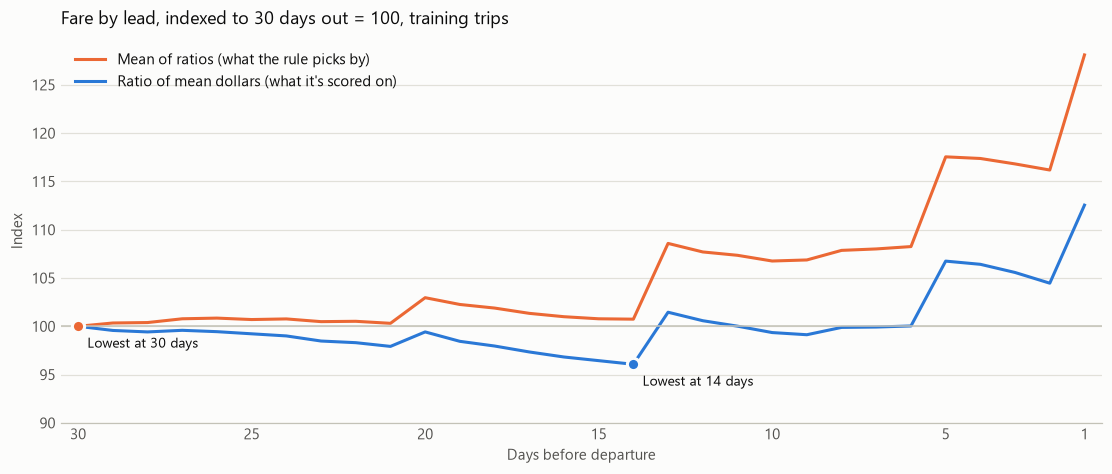

,Trips,Best lead by mean ratio,Best lead by mean dollars,Dollar saving vs 30 days
Departures,,,,
05-01 to 06-15,5222,30,30,0.00
06-15 to 07-05,3275,14,14,23.54
07-05 to 07-30,4702,21,14,16.59


All training trips: lowest mean dollars at 14 days, $9.55 below 30 days


In [5]:
relative = buy.div(buy[cfg.start_lead], axis=0)
compare = pd.DataFrame({"Mean of ratios (what the rule picks by)": 100 * relative.mean(),
                        "Ratio of mean dollars (what it's scored on)": 100 * buy.mean() / buy[cfg.start_lead].mean()})
fig, ax = plt.subplots(figsize=(10, 4.2))
for (name, values), color in zip(compare.items(), (ORANGE, BLUE)):
    ax.plot(values.index, values, color=color, label=name)
    best = values.idxmin()
    ax.plot(best, values[best], "o", ms=8, color=color, mec=SURFACE, mew=2, zorder=3)
    ax.annotate(f"Lowest at {best} days", (best, values[best]), xytext=(6, -14), textcoords="offset points", fontsize=9)
ax.axhline(100, color=AXIS, linewidth=1)
ax.set(title="Fare by lead, indexed to 30 days out = 100, training trips", ylabel="Index")
ax.legend(loc="upper left")
ax.set_ylim(90, None)
lead_axis(ax)
plt.show()

periods = [("2022-05-01", "2022-06-15"), ("2022-06-15", "2022-07-05"), ("2022-07-05", "2022-07-30")]
rows = []
for start, end in periods:
    part = buy[(flight_dates >= start) & (flight_dates < end)]
    dollars = part.mean()
    rows.append({
        "Departures": f"{start[5:]} to {end[5:]}",
        "Trips": len(part),
        "Best lead by mean ratio": part.div(part[cfg.start_lead], axis=0).mean().idxmin(),
        "Best lead by mean dollars": dollars.idxmin(),
        "Dollar saving vs 30 days": round(dollars[cfg.start_lead] - dollars.min(), 2),
    })
display(pd.DataFrame(rows).set_index("Departures"))
print(f"All training trips: lowest mean dollars at {buy.mean().idxmin()} days, ${buy[30].mean() - buy.mean().min():.2f} below 30 days")

## 1.5 How often does waiting pay?

Averages hide a wide spread. Each panel compares waiting until that lead with buying at 30 days, trip by trip. At 14 days, waiting is close to a coin flip: 48% of trips are cheaper and 45% dearer. By 1 day out, 70% cost more and the median trip pays $35 extra.

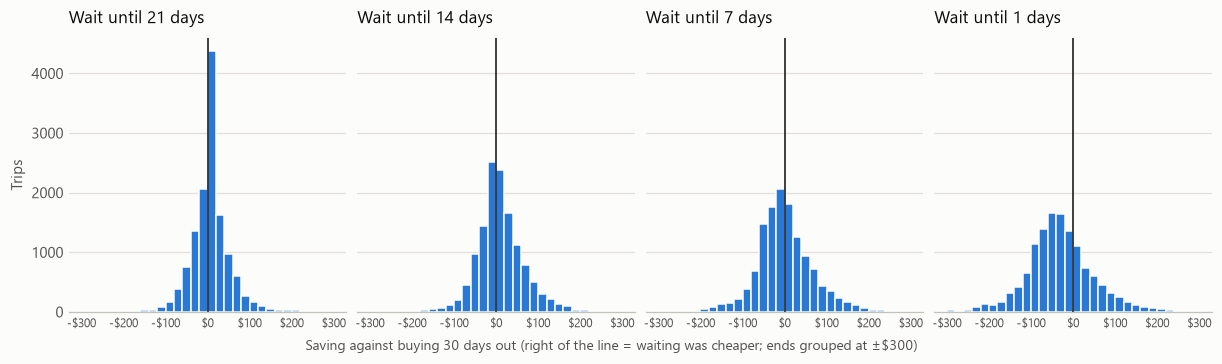

,Cheaper,Same,Dearer,Mean saving ($),Median saving ($),5th percentile ($),95th percentile ($)
Wait until (days out),,,,,,,
21,42%,20%,37%,5.05,0.00,-65,81
14,48%,7%,45%,9.55,0.00,-71,110
7,44%,3%,53%,0.19,-6.00,-103,120
1,29%,2%,70%,-30.44,-35.00,-155,109


In [6]:
panels = [21, 14, 7, 1]
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2), sharey=True, sharex=True)
rows = []
for ax, lead in zip(axes, panels):
    saving = (buy[cfg.start_lead] - buy[lead]).dropna()
    ax.hist(saving.clip(-300, 300), bins=np.arange(-300, 301, 20), color=BLUE, edgecolor=SURFACE, linewidth=1)
    ax.axvline(0, color=INK, linewidth=1)
    ax.set_title(f"Wait until {lead} days", fontsize=11)
    ax.xaxis.set_major_formatter(DOLLARS)
    ax.tick_params(axis="x", labelsize=8)
    rows.append({"Wait until (days out)": lead, "Cheaper": (saving > 0).mean(), "Same": (saving == 0).mean(),
                 "Dearer": (saving < 0).mean(), "Mean saving ($)": saving.mean(), "Median saving ($)": saving.median(),
                 "5th percentile ($)": saving.quantile(.05), "95th percentile ($)": saving.quantile(.95)})
axes[0].set_ylabel("Trips")
fig.supxlabel("Saving against buying 30 days out (right of the line = waiting was cheaper; ends grouped at ±$300)", fontsize=9, color=INK_2)
plt.show()
display(pd.DataFrame(rows).set_index("Wait until (days out)").style.format({
    "Cheaper": "{:.0%}", "Same": "{:.0%}", "Dearer": "{:.0%}", "Mean saving ($)": "{:.2f}", "Median saving ($)": "{:.2f}",
    "5th percentile ($)": "{:.0f}", "95th percentile ($)": "{:.0f}"}))

## 1.6 Route-specific timing is mostly noise until late in the window

Each dot is a route. The test here: if a route's pattern is real, its early-period behaviour should predict its later behaviour, with dots along the diagonal.

At 21 days out there's almost no relationship, and it only becomes strong close to departure. Each route has only about 56 training trips, and neighbouring departures share the same price moves, so the true sample is even smaller. Picking the lowest of 30 noisy numbers per route tends to find luck, which fits the per-route rule losing to the simple one in the final test (section 1.9).

In the first panel most dots sit below the diagonal. Nearly every route looked better in the later departures, which again points to a market-wide move rather than anything about the route.

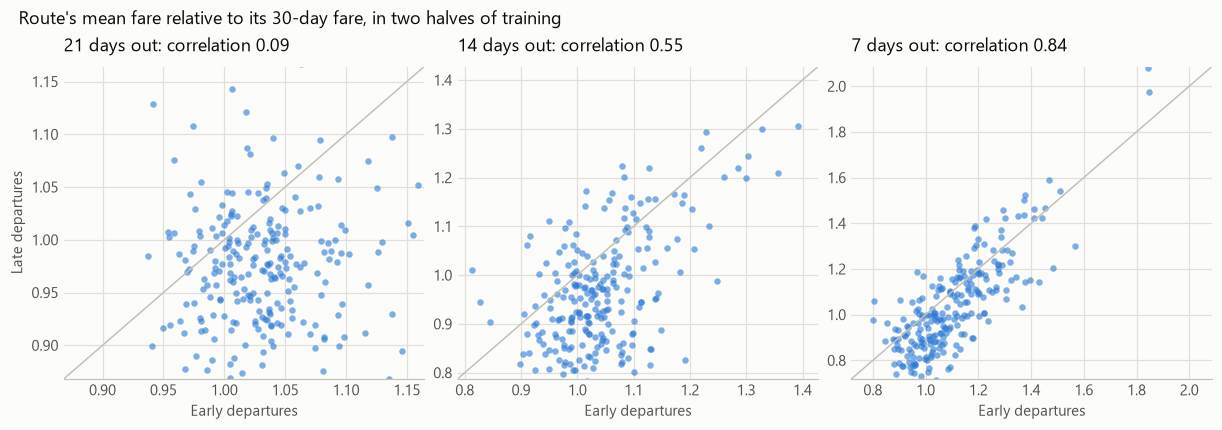

Routes compared: 234. Median training trips per route: 57
Same best lead in both halves: 13% of routes. Within 3 days: 41%

Mean fare 1 day out against 30 days out, lowest and highest routes:


,ratio
DEN-LGA,0.73
ORD-BOS,0.74
JFK-DEN,0.75
DEN-JFK,0.78
IAD-OAK,0.79
LGA-IAD,2.36
BOS-LGA,2.41
BOS-JFK,2.47
CLT-ATL,2.56
ATL-CLT,2.58


In [7]:
middle = pd.Series(flight_dates).median()
early, late = relative[flight_dates < middle], relative[flight_dates >= middle]
route_levels = ["origin", "destination"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharex=False, sharey=False)
for ax, lead in zip(axes, (21, 14, 7)):
    joined = pd.concat([early[lead].groupby(level=route_levels).mean(), late[lead].groupby(level=route_levels).mean()], axis=1, keys=["early", "late"]).dropna()
    low, high = np.nanquantile(joined.to_numpy(), [.005, .995])
    ax.plot([low, high], [low, high], color=AXIS, linewidth=1)
    ax.scatter(joined["early"], joined["late"], s=18, color=BLUE, alpha=.6, linewidths=0)
    ax.set(xlim=(low, high), ylim=(low, high), xlabel="Early departures", title=f"{lead} days out: correlation {joined.corr().iloc[0, 1]:.2f}")
    ax.grid(True, axis="both")
axes[0].set_ylabel("Late departures")
fig.suptitle("Route's mean fare relative to its 30-day fare, in two halves of training", x=0.01, ha="left", fontsize=12)
plt.show()

lead_early = buy[flight_dates < middle].groupby(level=route_levels).apply(lambda trips: best_fixed_lead(trips, cfg) if len(trips) >= 10 else np.nan)
lead_late = buy[flight_dates >= middle].groupby(level=route_levels).apply(lambda trips: best_fixed_lead(trips, cfg) if len(trips) >= 10 else np.nan)
leads = pd.concat([lead_early, lead_late], axis=1, keys=["early", "late"]).dropna()
trips_per_route = train.groupby(level=route_levels).size()
print(f"Routes compared: {len(leads)}. Median training trips per route: {trips_per_route.median():.0f}")
print(f"Same best lead in both halves: {(leads['early'] == leads['late']).mean():.0%} of routes. Within 3 days: {((leads['early'] - leads['late']).abs() <= 3).mean():.0%}")

last_day = relative[1].groupby(level=route_levels).mean().sort_values()
last_day.index = [f"{origin}-{destination}" for origin, destination in last_day.index]
print("\nMean fare 1 day out against 30 days out, lowest and highest routes:")
display(pd.concat([last_day.head(5), last_day.tail(5)]).round(2).to_frame("ratio"))

## 1.7 Distance explains most of a route's price

Distance alone accounts for most of the price difference between routes. Labelled routes sit furthest above or below the trend for their distance. Prices come from 7 to 30 days out on training quotes.

Distance here is the travel distance of the itineraries offered, so it includes connections. That's why SFO-OAK, two airports about 10 miles apart, shows as 677 miles.

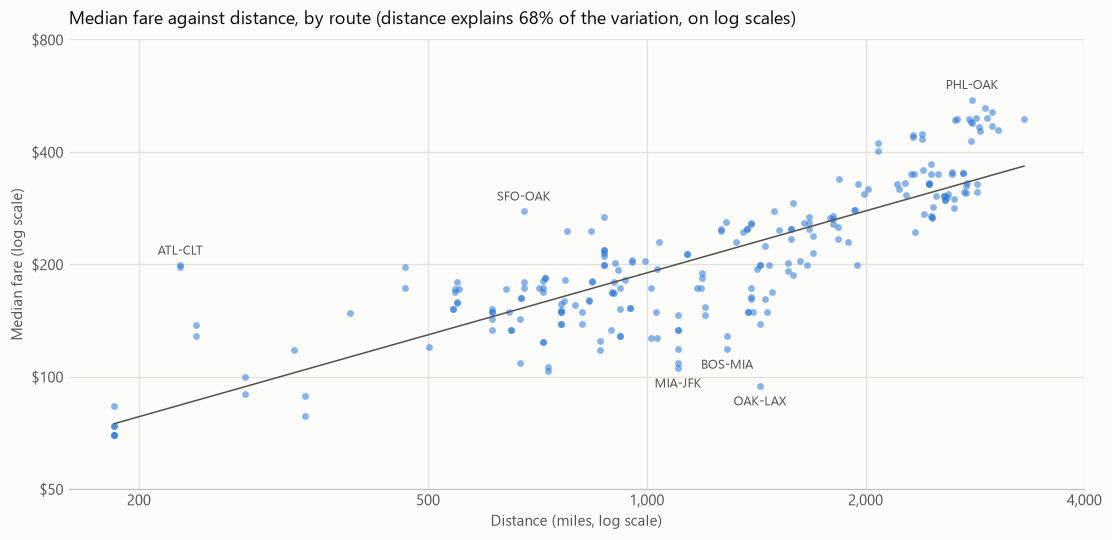

Each doubling of distance goes with about 47% higher fares


,,price,distance,vs_trend,per_mile
origin,destination,,,,
OAK,LAX,94.6,1432.0,0.41,0.07
MIA,JFK,105.6,1104.0,0.53,0.10
JFK,MIA,108.6,1104.0,0.54,0.10
BOS,MIA,118.6,1289.0,0.54,0.09
PHL,OAK,551.7,2802.5,1.65,0.20
SFO,OAK,277.2,677.0,1.81,0.41
CLT,ATL,197.1,228.0,2.35,0.86
ATL,CLT,198.6,228.0,2.37,0.87


In [8]:
route_price = (
    train_quotes[train_quotes["days_to_departure"].between(7, 30)]
    .groupby(route_levels).agg(price=("price", "median"), distance=("distance", "median")).dropna()
)
log_d, log_p = np.log(route_price["distance"]), np.log(route_price["price"])
slope, intercept = np.polyfit(log_d, log_p, 1)
route_price["vs_trend"] = np.exp(log_p - (intercept + slope * log_d))
r_squared = np.corrcoef(log_d, log_p)[0, 1] ** 2

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.scatter(route_price["distance"], route_price["price"], s=20, color=BLUE, alpha=.55, linewidths=0)
span = np.array([route_price["distance"].min(), route_price["distance"].max()])
ax.plot(span, np.exp(intercept) * span ** slope, color=INK_2, linewidth=1)
ax.set_xscale("log")
ax.set_yscale("log")
ticks_x, ticks_y = [200, 500, 1000, 2000, 4000], [50, 100, 200, 400, 800]
ax.set_xticks(ticks_x, [f"{tick:,}" for tick in ticks_x])
ax.set_yticks(ticks_y, [f"${tick}" for tick in ticks_y])
ax.minorticks_off()
ax.grid(True, axis="both")
extremes = pd.concat([route_price.nlargest(4, "vs_trend"), route_price.nsmallest(4, "vs_trend")])
seen = set()
for (origin, destination), row in extremes.iterrows():
    pair = frozenset((origin, destination))
    if pair in seen:
        continue
    seen.add(pair)
    above = row["vs_trend"] > 1
    ax.annotate(f"{origin}-{destination}", (row["distance"], row["price"]), xytext=(0, 7 if above else -13),
                textcoords="offset points", ha="center", fontsize=8.5, color=INK_2)
ax.set(title=f"Median fare against distance, by route (distance explains {r_squared:.0%} of the variation, on log scales)",
       xlabel="Distance (miles, log scale)", ylabel="Median fare (log scale)")
plt.show()
print(f"Each doubling of distance goes with about {100 * (2 ** slope - 1):.0f}% higher fares")
display(route_price.assign(per_mile=lambda d: d["price"] / d["distance"]).sort_values("vs_trend").round(2).iloc[[*range(4), *range(-4, 0)]])

## 1.8 Airlines and departure days

**Which airlines set the fare.** The series excludes Spirit and Frontier because their fares aren't flagged as basic economy but may leave out bags. JetBlue has the same gap: none of its rows are flagged either. It stays in the series and is often the cheapest, so some of its fares may not be like-for-like.

**What the exclusion changes.** The second chart recomputes the cheapest fare with and without Spirit and Frontier. It uses all training quotes rather than usable trips, so its levels differ a little from section 1.3.

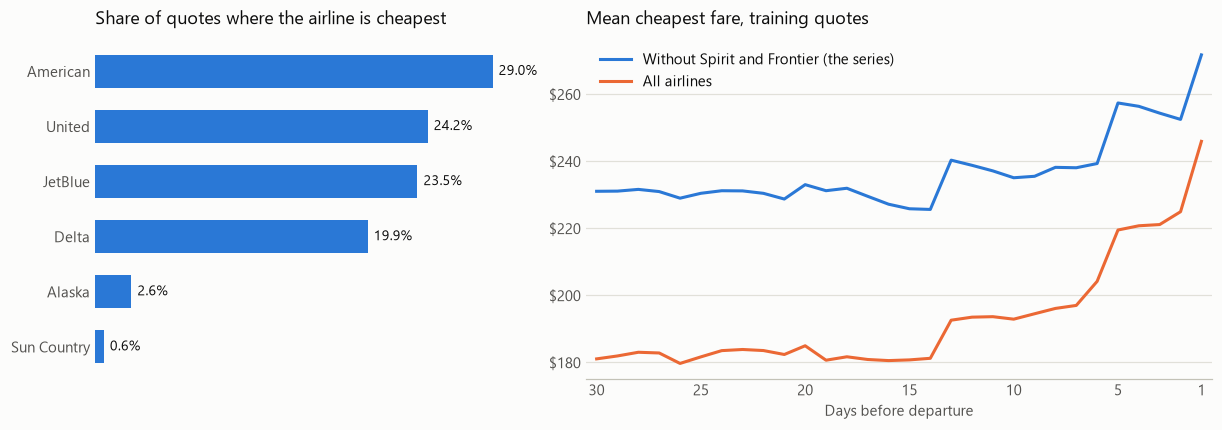

,name,itineraries,share_flagged_basic,share_cheapest,median_when_cheapest
airline,,,,,
AA,American,"14,279,759",2.1%,29.0%,$193
DL,Delta,"12,216,338",15.7%,19.9%,$309
UA,United,"11,341,781",7.7%,24.2%,$189
B6,JetBlue,"3,950,659",0.0%,23.5%,$155
NK,Spirit,"3,088,887",0.0%,excluded,excluded
AS,Alaska,"2,175,653",4.8%,2.6%,$405
F9,Frontier,"623,900",0.0%,excluded,excluded
SY,Sun Country,"168,218",0.0%,0.6%,$304


Effect of the exclusion on the mean cheapest fare: $50 at 30 days, $26 at 1 day


In [9]:
con = duckdb.connect()
con.execute("SET threads = 4")  # leave room for anything else running on this machine
itineraries = f"read_parquet('{ITINERARIES_PATH.as_posix()}')"
training_filter = f"searchDate < DATE '{SPLIT.date()}'"

airlines = con.execute(f"""
    SELECT split_part(segmentsAirlineCode, '||', 1) AS airline,
           count(*) AS itineraries,
           avg(isBasicEconomy::INT) AS share_flagged_basic
    FROM {itineraries} WHERE {training_filter} GROUP BY 1
""").df().set_index("airline")
airlines = airlines.join(train_quotes["cheapest_airline"].value_counts(normalize=True).rename("share_cheapest"))
airlines = airlines.join(train_quotes.groupby("cheapest_airline")["price"].median().rename("median_when_cheapest"))
airlines = airlines.sort_values("itineraries", ascending=False).head(8)
names = {"AA": "American", "DL": "Delta", "UA": "United", "B6": "JetBlue", "NK": "Spirit", "AS": "Alaska", "F9": "Frontier", "SY": "Sun Country"}
airlines.insert(0, "name", airlines.index.map(names))

codes = "|".join(EXCLUDED_AIRLINES)
with_without = con.execute(rf"""
    WITH quotes AS (
        SELECT origin, destination, flightDate, searchDate, days_to_departure AS lead, totalFare,
               regexp_matches(segmentsAirlineCode, '(^|\|)({codes})(\||$)') AS excluded
        FROM {itineraries}
        WHERE {training_filter} AND days_to_departure BETWEEN 1 AND 30 AND totalFare > 0
            AND isBasicEconomy = false AND regexp_full_match(segmentsCabinCode, 'coach(\|\|coach)*')
    ),
    cheapest AS (
        SELECT lead, min(totalFare) AS all_airlines, min(totalFare) FILTER (WHERE NOT excluded) AS without_excluded
        FROM quotes GROUP BY origin, destination, flightDate, searchDate, lead
    )
    SELECT lead, avg(all_airlines) AS all_airlines, avg(without_excluded) AS without_excluded FROM cheapest GROUP BY lead ORDER BY lead
""").df().set_index("lead")

shown = airlines.dropna(subset=["share_cheapest"]).sort_values("share_cheapest")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), width_ratios=[1, 1.5])
left.barh(shown["name"], 100 * shown["share_cheapest"], color=BLUE, height=.6)
for name, share in zip(shown["name"], shown["share_cheapest"]):
    left.annotate(f"{share:.1%}", (100 * share, name), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
left.grid(False)
left.spines["bottom"].set_visible(False)
left.set_xticks([])
left.set_title("Share of quotes where the airline is cheapest")

right.plot(with_without.index, with_without["without_excluded"], color=BLUE, label="Without Spirit and Frontier (the series)")
right.plot(with_without.index, with_without["all_airlines"], color=ORANGE, label="All airlines")
right.yaxis.set_major_formatter(DOLLARS)
right.set_title("Mean cheapest fare, training quotes")
right.legend(loc="upper left")
lead_axis(right)
plt.show()

display(airlines.style.format({"itineraries": "{:,.0f}", "share_flagged_basic": "{:.1%}", "share_cheapest": "{:.1%}", "median_when_cheapest": "${:.0f}"}, na_rep="excluded"))
gap = with_without["without_excluded"] - with_without["all_airlines"]
print(f"Effect of the exclusion on the mean cheapest fare: ${gap.loc[30]:.0f} at 30 days, ${gap.loc[1]:.0f} at 1 day")

**Seat counts are limited by airline.** `seats_remaining` is a model feature, but the number shown mostly tops out at 7 on some airlines and 9 on others. Comparing raw values across airlines partly compares the airlines themselves.

**Departure day and lead.** Each cell is the mean fare relative to that route's median, so cheap and dear routes compare. Tuesdays and Wednesdays are cheapest at every lead and Sundays dearest. The gap narrows close to departure but doesn't close.

Share of each airline's cheapest quotes showing that many seats:


seats_remaining,5,6,7,8,9,10
cheapest_airline,,,,,,
AA,5%,4%,54%,0%,0%,2%
UA,7%,6%,5%,4%,38%,0%
DL,7%,6%,6%,5%,33%,0%
B6,1%,1%,95%,0%,0%,0%
AS,6%,6%,48%,0%,0%,0%


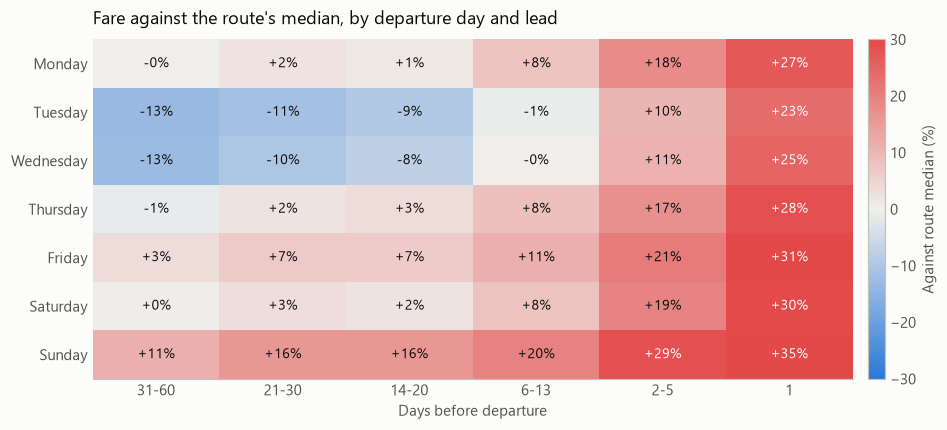

In [10]:
majors = ["AA", "UA", "DL", "B6", "AS"]
seats = pd.crosstab(train_quotes["cheapest_airline"], train_quotes["seats_remaining"], normalize="index").loc[majors]
print("Share of each airline's cheapest quotes showing that many seats:")
display(seats.loc[:, seats.columns >= 5].style.format("{:.0%}"))

bins = [0, 1, 5, 13, 20, 30, 60]
labels = ["1", "2-5", "6-13", "14-20", "21-30", "31-60"]
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
route_median = train_quotes.groupby(route_levels)["price"].transform("median")
table = (
    train_quotes.assign(ratio=train_quotes["price"] / route_median,
                        weekday=train_quotes["flightDate"].dt.day_name(),
                        bucket=pd.cut(train_quotes["days_to_departure"], bins, labels=labels))
    .pivot_table(index="weekday", columns="bucket", values="ratio", aggfunc="mean", observed=True)
    .reindex(index=weekdays, columns=labels[::-1])
)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
image = ax.imshow(100 * (table - 1), cmap=DIVERGING, norm=TwoSlopeNorm(vcenter=0, vmin=-30, vmax=30), aspect="auto")
ax.set_xticks(range(len(table.columns)), table.columns)
ax.set_yticks(range(len(table.index)), table.index)
for y, row in enumerate(100 * (table - 1).to_numpy()):
    for x, value in enumerate(row):
        ax.text(x, y, f"{value:+.0f}%", ha="center", va="center", fontsize=9, color="#ffffff" if abs(value) > 22 else INK)
ax.grid(False)
ax.set(title="Fare against the route's median, by departure day and lead", xlabel="Days before departure")
fig.colorbar(image, ax=ax, label="Against route median (%)", pad=0.02)
plt.show()

## 1.9 Final test results

These are the saved results from `reports/`, plotted as they are. Each dot is the mean saving per test trip against buying 30 days out, and the bars are 95% confidence intervals resampled by departure date.

- **The models beat the baselines,** and LightGBM captures about a quarter of what perfect hindsight could save.
- **The gain doesn't survive a one-day delay.** If each purchase goes through a day later, both models lose money against buying 30 days out, even though that baseline gets the same delay. The edge depends on catching low fares on the day they appear, which a real buyer may not manage.
- The saved "best fixed lead" is the same rule as buying 30 days out, so its saving is zero by construction.

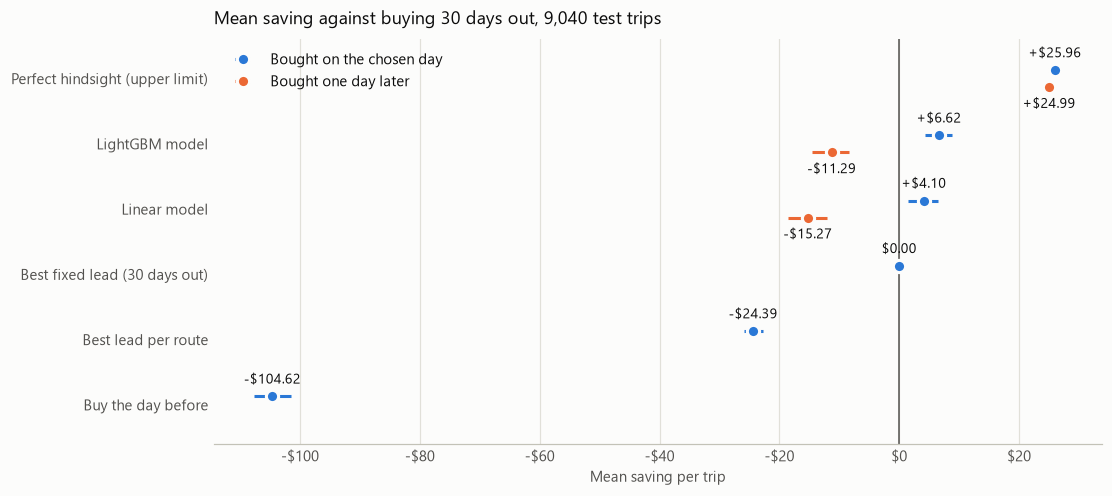

,mean_price,mean_saving,saving_ci_low,saving_ci_high,share_trips_cheaper,share_trips_dearer,p95_overpay
policy,,,,,,,
buy_first_day,181.56,0.00,0.00,0.00,0.00,0.00,0.00
buy_last_day,286.18,-104.62,-107.65,-101.54,0.05,0.94,218.50
best_fixed_lead,181.56,0.00,0.00,0.00,0.00,0.00,0.00
best_lead_by_route,205.95,-24.39,-25.96,-22.82,0.19,0.51,124.91
hindsight,155.60,25.96,24.85,27.07,0.66,0.00,0.00
model_lightgbm,174.94,6.62,4.32,8.86,0.40,0.25,76.00
model_linear,177.46,4.10,1.49,6.47,0.38,0.26,82.00


With a one-day purchase delay:


,mean_price,mean_saving,saving_ci_low,saving_ci_high,share_trips_cheaper,share_trips_dearer,p95_overpay
policy,,,,,,,
buy_first_day,181.53,0.00,0.00,0.00,0.00,0.00,0.0
model_lightgbm,192.82,-11.29,-14.50,-8.34,0.26,0.38,120.0
model_linear,196.80,-15.27,-18.64,-12.01,0.24,0.41,128.0
hindsight,156.54,24.99,23.88,26.10,0.64,0.00,0.0


Models chosen with margin {'lightgbm': 0.0, 'linear': 0.0}. LightGBM buys at 19.6 days on average, and on the first day for 22% of trips


In [11]:
summary = pd.read_csv(REPORTS / "model_summary.csv", index_col=0)
delayed = pd.read_csv(REPORTS / "model_summary_one_day_delay.csv", index_col=0)
model_setup = json.loads((REPORTS / "model_setup.json").read_text())
rule_names = {
    "hindsight": "Perfect hindsight (upper limit)",
    "model_lightgbm": "LightGBM model",
    "model_linear": "Linear model",
    "best_fixed_lead": f"Best fixed lead ({setup['best_fixed_lead']} days out)",
    "best_lead_by_route": "Best lead per route",
    "buy_last_day": "Buy the day before",
}
order = list(rule_names)[::-1]
positions = pd.Series(range(len(order)), index=order)


def plot_rules(ax, results, color, label, offset, label_side):
    results = results.reindex([rule for rule in order if rule in results.index])
    y = positions[results.index] + offset
    ax.errorbar(results["mean_saving"], y, xerr=[results["mean_saving"] - results["saving_ci_low"], results["saving_ci_high"] - results["mean_saving"]],
                fmt="o", ms=8, color=color, mec=SURFACE, mew=2, ecolor=color, elinewidth=2, label=label)
    for row, value in zip(y, results["mean_saving"]):
        text = f"{'+' if value > 0 else '-' if value < 0 else ''}${abs(value):.2f}"
        ax.annotate(text, (value, row), xytext=(0, label_side), textcoords="offset points", ha="center", va="center", fontsize=9)


fig, ax = plt.subplots(figsize=(10, 4.4))
plot_rules(ax, summary, BLUE, "Bought on the chosen day", .13, 11)
plot_rules(ax, delayed.drop(index="buy_first_day"), ORANGE, "Bought one day later", -.13, -11)
ax.set_yticks(positions, [rule_names[rule] for rule in order])
ax.axvline(0, color=INK_2, linewidth=1)
ax.xaxis.set_major_formatter(DOLLARS)
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.set_ylim(-.6, len(order) - .4)
ax.set(title=f"Mean saving against buying 30 days out, {int(summary['trips'].iloc[0]):,} test trips", xlabel="Mean saving per trip")
ax.legend(loc="upper left")
plt.show()

columns = ["mean_price", "mean_saving", "saving_ci_low", "saving_ci_high", "share_trips_cheaper", "share_trips_dearer", "p95_overpay"]
display(summary[columns].round(2))
print("With a one-day purchase delay:")
display(delayed[columns].round(2))
print(f"Models chosen with margin {model_setup['margins']}. LightGBM buys at {model_setup['mean_bought_at']['lightgbm']:.1f} days on average, and on the first day for {model_setup['share_bought_first_day']['lightgbm']:.0%} of trips")

**What LightGBM relied on.** The biggest signal is how a fare compares with departures a few days either side, followed by how it compares with the route's other fares that day. Both describe whether this fare looks low right now, which would fit an edge that fades after a day. Seat counts, flagged as airline-limited in section 1.8, contribute little.

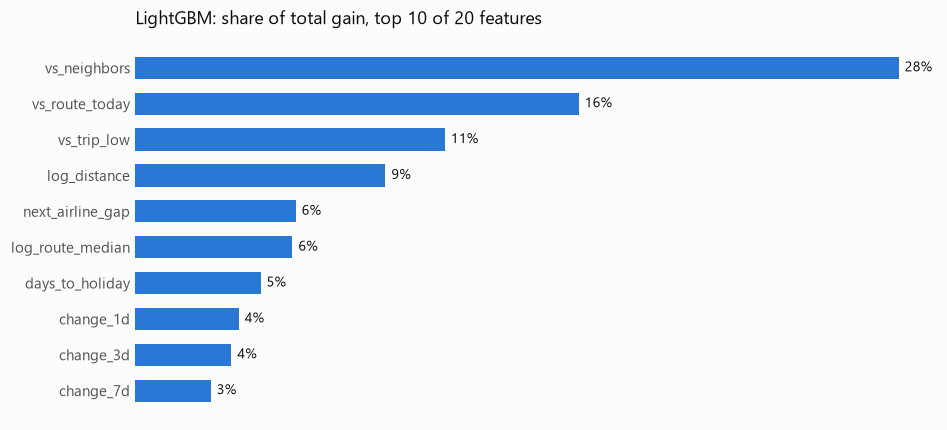

In [12]:
importance = pd.read_csv(REPORTS / "model_feature_importance.csv", index_col=0)["share_of_gain"].sort_values()
top_features = importance.tail(10)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.barh(top_features.index, 100 * top_features, color=BLUE, height=.62)
for y, value in enumerate(top_features):
    ax.annotate(f"{value:.0%}", (100 * value, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.grid(False)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("LightGBM: share of total gain, top 10 of 20 features")
plt.show()

## 1.10 Did the training pattern hold in the test period?

Training suggested waiting until 14 days out. It didn't hold: on test trips, waiting lost money at every lead shown, and the best lead by mean dollars was 29 days.

The market offers a likely reason. Fares were falling for much of the training period, while on test trips they rose from a low in early August, so a traveller who waited was moving against the market.

The last chart shows which fares moved. The 30-day fare fell from about $280 to about $170 between mid-June and late August departures, while the day-before fare stayed between about $260 and $295. Early fares carry most of the market swings here.

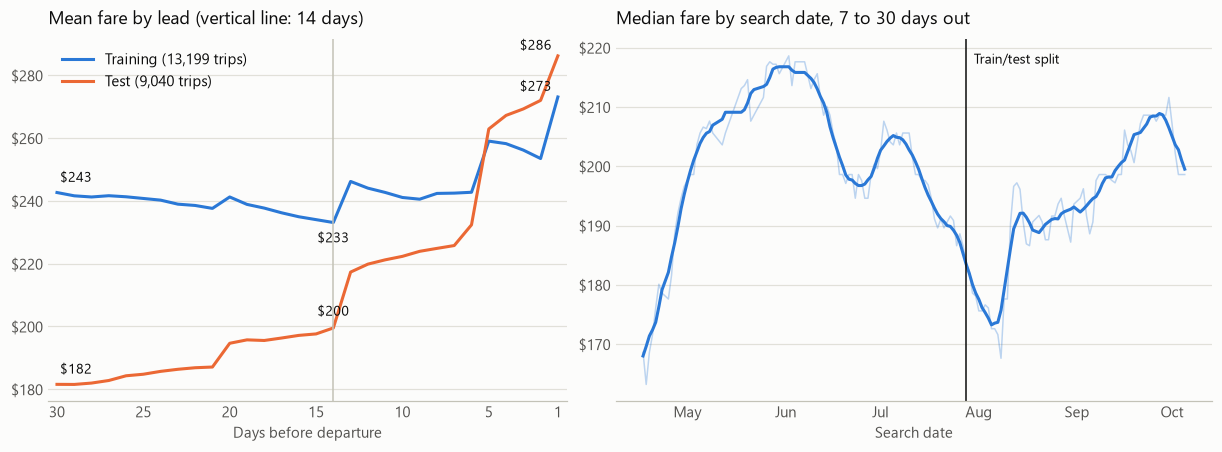

,Training saving ($),Test saving ($),Test: trips cheaper,Test: trips dearer
Wait until (days out),,,,
21,5.05,-5.52,33%,41%
14,9.55,-17.96,28%,61%
7,0.19,-44.21,16%,81%
1,-30.44,-104.62,5%,94%


Market after the split: low $173 on 2022-08-05, end $200 (+15% from the low)
Best lead on test trips by mean dollars: 29 days. Mean at 30 days: $181.56


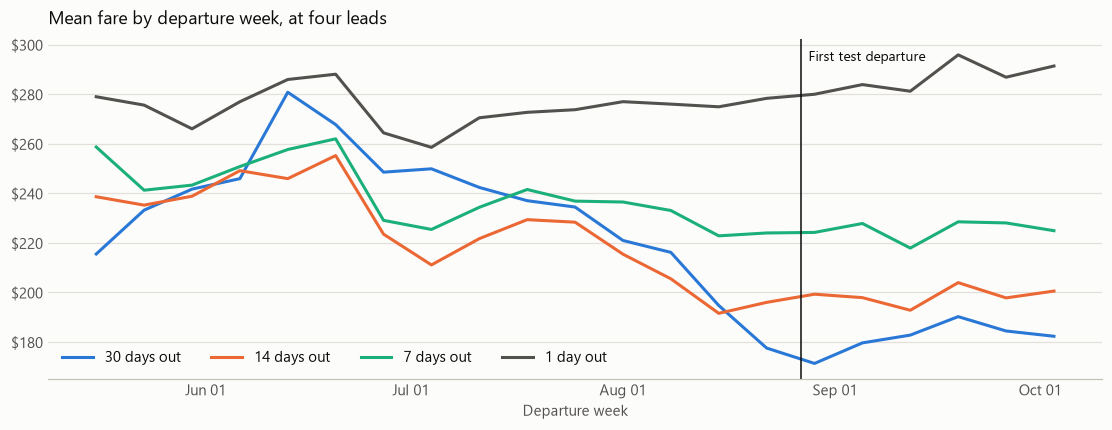

In [13]:
test_buy = test.bfill(axis=1)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), width_ratios=[1, 1.15])
for values, color, name in ((buy.mean(), BLUE, f"Training ({len(buy):,} trips)"), (test_buy.mean(), ORANGE, f"Test ({len(test_buy):,} trips)")):
    left.plot(values.index, values, color=color, label=name)
    left.annotate(f"${values[30]:.0f}", (30, values[30]), xytext=(2, 7), textcoords="offset points", fontsize=9)
    left.annotate(f"${values[14]:.0f}", (14, values[14]), xytext=(0, -13 if color == BLUE else 8), textcoords="offset points", ha="center", fontsize=9)
    left.annotate(f"${values[1]:.0f}", (1, values[1]), xytext=(-4, 4), textcoords="offset points", ha="right", fontsize=9)
left.axvline(14, color=AXIS, linewidth=1)
left.yaxis.set_major_formatter(DOLLARS)
left.set_title("Mean fare by lead (vertical line: 14 days)")
left.legend(loc="upper left")
lead_axis(left)

whole_market = market_level(series)
whole_smooth = whole_market.rolling(7, center=True, min_periods=4).mean()
right.plot(whole_market.index, whole_market, color=BLUE, linewidth=1, alpha=.3)
right.plot(whole_smooth.index, whole_smooth, color=BLUE)
right.axvline(SPLIT, color=INK, linewidth=1)
right.annotate("Train/test split", (SPLIT, whole_smooth.max()), xytext=(5, 2), textcoords="offset points", fontsize=9)
right.yaxis.set_major_formatter(DOLLARS)
right.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
right.set(title="Median fare by search date, 7 to 30 days out", xlabel="Search date")
plt.show()

waits = [21, 14, 7, 1]
held_up = pd.DataFrame({
    "Training saving ($)": {lead: buy[30].mean() - buy[lead].mean() for lead in waits},
    "Test saving ($)": {lead: test_buy[30].mean() - test_buy[lead].mean() for lead in waits},
    "Test: trips cheaper": {lead: (test_buy[lead] < test_buy[30]).mean() for lead in waits},
    "Test: trips dearer": {lead: (test_buy[lead] > test_buy[30]).mean() for lead in waits},
}).rename_axis("Wait until (days out)")
display(held_up.style.format({"Training saving ($)": "{:.2f}", "Test saving ($)": "{:.2f}", "Test: trips cheaper": "{:.0%}", "Test: trips dearer": "{:.0%}"}))

first_quotes = whole_smooth[(whole_smooth.index >= SPLIT)].dropna()
print(f"Market after the split: low ${first_quotes.min():.0f} on {first_quotes.idxmin().date()}, end ${first_quotes.iloc[-1]:.0f} ({100 * (first_quotes.iloc[-1] / first_quotes.min() - 1):+.0f}% from the low)")
print(f"Best lead on test trips by mean dollars: {test_buy.mean().idxmin()} days. Mean at 30 days: ${test_buy[30].mean():.2f}")

all_buy = curves.bfill(axis=1)
weeks = all_buy.index.get_level_values("flightDate").to_period("W").start_time
weekly_leads = all_buy[[30, 14, 7, 1]].groupby(weeks).mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
for (lead, values), color in zip(weekly_leads.items(), (BLUE, ORANGE, AQUA, INK_2)):
    ax.plot(values.index, values, color=color, label=f"{lead} day{'s' if lead > 1 else ''} out")
ax.axvline(SPLIT + pd.Timedelta(days=cfg.start_lead), color=INK, linewidth=1)
ax.annotate("First test departure", (SPLIT + pd.Timedelta(days=cfg.start_lead), weekly_leads.to_numpy().max()), xytext=(5, -4), textcoords="offset points", fontsize=9)
ax.yaxis.set_major_formatter(DOLLARS)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set(title="Mean fare by departure week, at four leads", xlabel="Departure week")
ax.legend(ncols=4, loc="lower left")
plt.show()

---
# Part 2: Germany

This data is a different market and era from the US fares, and in euros, so the two parts can't be compared directly. The scraper began on 2026-11-03, so **it can't yet show how any fare moves as departure approaches**. That needs the same departures seen on many days. The cells read every snapshot in the folder, so they pick up new data on each re-run, but the fare charts below use the latest snapshot only.

In [14]:
eurostat = pd.read_csv(GERMANY / "eurostat" / "germany_air_fare_index.csv")
eurostat["period"] = pd.to_datetime(eurostat["period"])


def load_fares(source):
    files = sorted((GERMANY / "fares" / source).rglob("*.csv.gz"))
    fares = pd.concat([pd.read_csv(file) for file in files], ignore_index=True)
    fares["snapshot_date"] = pd.to_datetime(fares["snapshot_date"])
    fares["departure_date"] = pd.to_datetime(fares["departure_date"])
    fares["lead"] = (fares["departure_date"] - fares["snapshot_date"]).dt.days
    return fares


ryanair_all, google_all = load_fares("ryanair"), load_fares("google_flights")
ryanair = ryanair_all[ryanair_all["snapshot_date"] == ryanair_all["snapshot_date"].max()]
google = google_all[google_all["snapshot_date"] == google_all["snapshot_date"].max()]
display(pd.DataFrame({
    "Snapshots": [ryanair_all["snapshot_date"].nunique(), google_all["snapshot_date"].nunique()],
    "Latest snapshot": [ryanair["snapshot_date"].max().date(), google["snapshot_date"].max().date()],
    "Fares in latest": [len(ryanair), len(google)],
    "Routes in latest": [ryanair.groupby(["origin", "destination"]).ngroups, google.groupby(["origin", "destination"]).ngroups],
}, index=["Ryanair", "Google Flights"]))

,Snapshots,Latest snapshot,Fares in latest,Routes in latest
Ryanair,1,2026-11-03,5111,268
Google Flights,1,2026-11-03,80,20


## 2.1 Official fare index since 1996

Eurostat's index shows how prices moved, not what a ticket cost. It's the only long history available for Germany. The pale line is monthly and the dark line is a 12-month average.

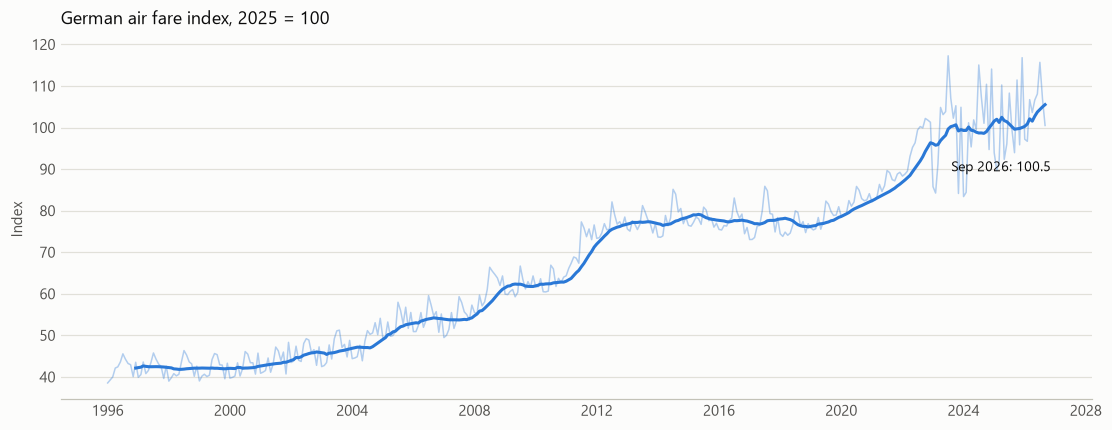

Annual mean: 1996 42, 2019 78, 2020 82, 2022 96, 2025 100
2025 against 2019: +28%. Largest one-month move: 25%
Typical one-month move: 1.7% in 2015-2019, 7.6% since 2024


In [15]:
overall = eurostat[(eurostat["coicop"] == "CP0733") & (eurostat["unit"] == "I25")].set_index("period")["value"].sort_index()
trend = overall.rolling(12).mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(overall.index, overall, color=BLUE, linewidth=1, alpha=.35)
ax.plot(trend.index, trend, color=BLUE)
ax.annotate(f"{overall.index[-1]:%b %Y}: {overall.iloc[-1]:.1f}", (overall.index[-1], overall.iloc[-1]), xytext=(4, -30),
            textcoords="offset points", ha="right", fontsize=9)
ax.set(title="German air fare index, 2025 = 100", ylabel="Index")
plt.show()
yearly = overall.groupby(overall.index.year).mean()
print(f"Annual mean: 1996 {yearly[1996]:.0f}, 2019 {yearly[2019]:.0f}, 2020 {yearly[2020]:.0f}, 2022 {yearly[2022]:.0f}, 2025 {yearly[2025]:.0f}")
print(f"2025 against 2019: {100 * (yearly[2025] / yearly[2019] - 1):+.0f}%. Largest one-month move: {100 * overall.pct_change().abs().max():.0f}%")
monthly_move = overall.pct_change().abs()
print(f"Typical one-month move: {100 * monthly_move['2015':'2019'].median():.1f}% in 2015-2019, {100 * monthly_move['2024':].median():.1f}% since 2024")

## 2.2 Domestic fares have overtaken international

Both series are 12-month averages indexed to 2015 = 100, so they share one scale. Domestic fares trailed for a decade and moved ahead in 2025.

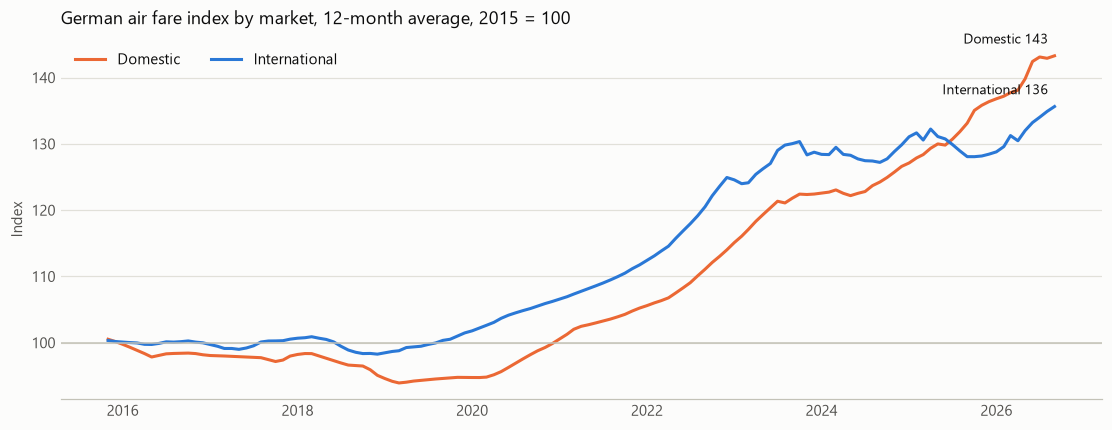

In [16]:
parts = eurostat[eurostat["unit"] == "I15"].pivot(index="period", columns="coicop", values="value")[["CP07331", "CP07332"]].dropna()
parts = parts.rolling(12).mean().dropna()
fig, ax = plt.subplots(figsize=(10, 3.8))
for code, name, color in (("CP07331", "Domestic", ORANGE), ("CP07332", "International", BLUE)):
    ax.plot(parts.index, parts[code], color=color, label=name)
    ax.annotate(f"{name} {parts[code].iloc[-1]:.0f}", (parts.index[-1], parts[code].iloc[-1]), xytext=(-4, 8),
                textcoords="offset points", ha="right", fontsize=9)
ax.axhline(100, color=AXIS, linewidth=1)
ax.set(title="German air fare index by market, 12-month average, 2015 = 100", ylabel="Index")
ax.legend(loc="upper left", ncols=2)
plt.show()

## 2.3 Seasonality

Each bar is how far that month usually sits from the 12-month trend, from 2015 on. 2020 and 2021 are left out because of the pandemic. July is the high point and January and February the low, about 15 points apart, so a fare snapshot from one season says little about another.

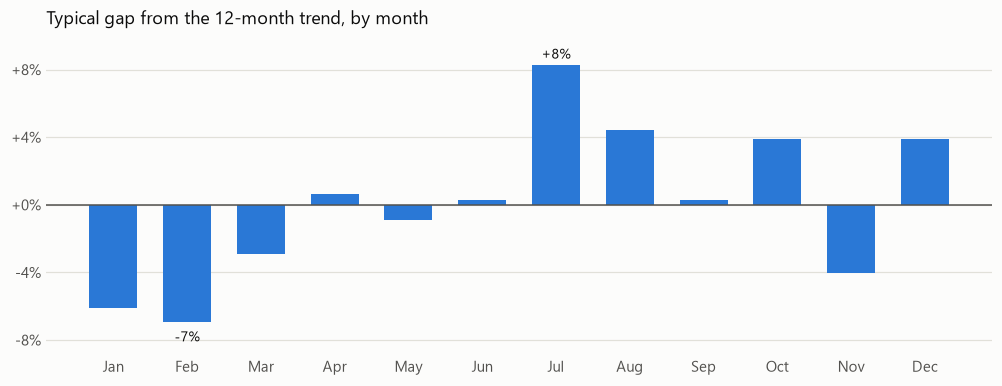

period,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Gap from trend (%),-6.1,-6.9,-2.9,0.6,-0.9,0.3,8.3,4.4,0.3,3.9,-4.0,3.9


In [17]:
centered = overall.rolling(12).mean().rolling(2).mean().shift(-6)
gaps = 100 * (overall / centered - 1)
gaps = gaps[(gaps.index.year >= 2015) & ~gaps.index.year.isin([2020, 2021])].dropna()
season = gaps.groupby(gaps.index.month).mean()
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(months, season.reindex(range(1, 13)), color=BLUE, width=.65)
for x, value in enumerate(season.reindex(range(1, 13))):
    if value in (season.max(), season.min()):
        ax.annotate(f"{value:+.0f}%", (x, value), xytext=(0, 4 if value > 0 else -13), textcoords="offset points", ha="center", fontsize=9)
ax.axhline(0, color=INK_2, linewidth=1)
ax.spines["bottom"].set_visible(False)
ax.set_ylim(season.min() - 2, season.max() + 1.5)
ax.set_yticks([-8, -4, 0, 4, 8])
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:+.0f}%"))
ax.set(title="Typical gap from the 12-month trend, by month")
plt.show()
display(season.round(1).rename(lambda month: months[month - 1]).to_frame("Gap from trend (%)").T)

## 2.4 Ryanair: fares by departure week

These are the cheapest fares to each destination across all 14 German airports Ryanair serves, seen on one day. **This isn't a booking curve:** a later departure is also a different season, so lead time and season can't be separated yet. Ryanair doesn't serve FRA or MUC, and base fares leave out bags and seats. The Christmas peak and the rise from late March stand out.

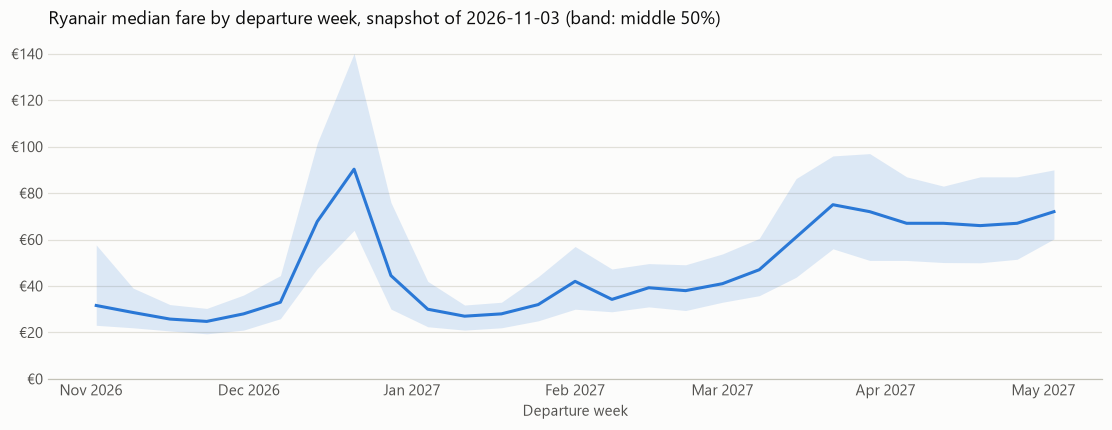

Lowest week: 2026-11-23 at €25. Highest week: 2026-12-21 at €90
Overall: median €43.75, cheapest €14.99, dearest €318.99


In [18]:
weekly = ryanair.groupby(pd.Grouper(key="departure_date", freq="W-MON", label="left"))["price"].describe(percentiles=[.25, .5, .75])
weekly = weekly[weekly["count"] >= 20]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(weekly.index, weekly["25%"], weekly["75%"], color=BLUE, alpha=.15, linewidth=0)
ax.plot(weekly.index, weekly["50%"], color=BLUE)
ax.yaxis.set_major_formatter(EUROS)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylim(0, None)
ax.set(title=f"Ryanair median fare by departure week, snapshot of {ryanair['snapshot_date'].max().date()} (band: middle 50%)", xlabel="Departure week")
plt.show()
peak, trough = weekly["50%"].idxmax(), weekly["50%"].idxmin()
print(f"Lowest week: {trough.date()} at €{weekly.loc[trough, '50%']:.0f}. Highest week: {peak.date()} at €{weekly.loc[peak, '50%']:.0f}")
print(f"Overall: median €{ryanair['price'].median():.2f}, cheapest €{ryanair['price'].min():.2f}, dearest €{ryanair['price'].max():.2f}")

## 2.5 Ryanair: departure airports and destinations

The same one-day snapshot, by airport. Each bar's label shows how many fares it rests on, and small airports such as PAD and SCN have few.

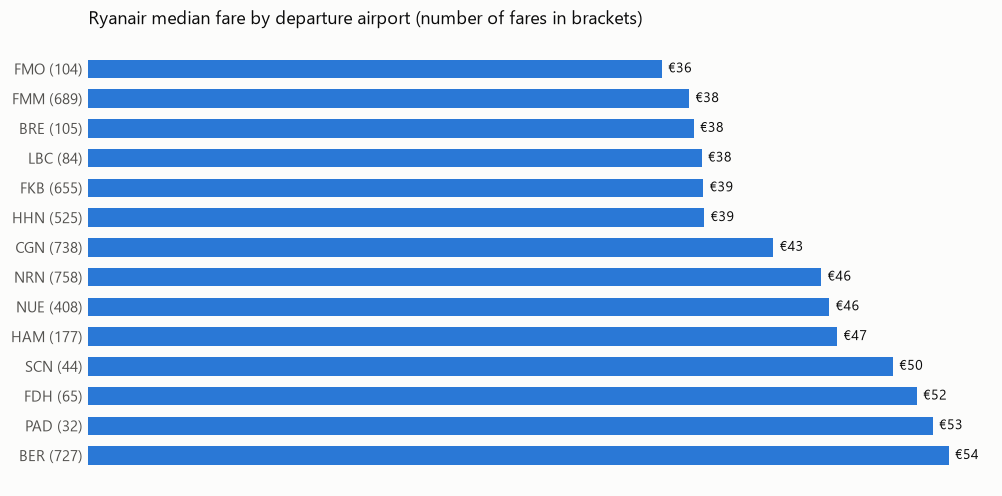

Cheapest and dearest destinations with at least 25 fares:


,median,count
destination,,
ZAG,26.41,78
BNX,26.61,52
BBU,26.66,45
STN,27.35,255
SUF,27.58,105
LIS,58.99,61
SKG,59.12,96
FUE,59.49,52
PFO,65.99,100


In [19]:
by_airport = ryanair.groupby("origin")["price"].agg(["median", "count"]).sort_values("median", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh([f"{code} ({count:,})" for code, count in zip(by_airport.index, by_airport["count"])], by_airport["median"], color=BLUE, height=.62)
for y, value in enumerate(by_airport["median"]):
    ax.annotate(f"€{value:.0f}", (value, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.grid(False)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Ryanair median fare by departure airport (number of fares in brackets)")
plt.show()

by_destination = ryanair.groupby("destination")["price"].agg(["median", "count"])
by_destination = by_destination[by_destination["count"] >= 25].sort_values("median")
print("Cheapest and dearest destinations with at least 25 fares:")
display(pd.concat([by_destination.head(5), by_destination.tail(5)]).round(2))

## 2.6 Google Flights: routes by departure date

Each column is one departure date, so each is also one lead time. Colour shows the fare against that route's own median, and blue is cheaper. The early-January column is high on most routes, which likely reflects returning holiday traffic rather than the 60-day lead. It's a useful reminder that one snapshot can't separate lead from date.

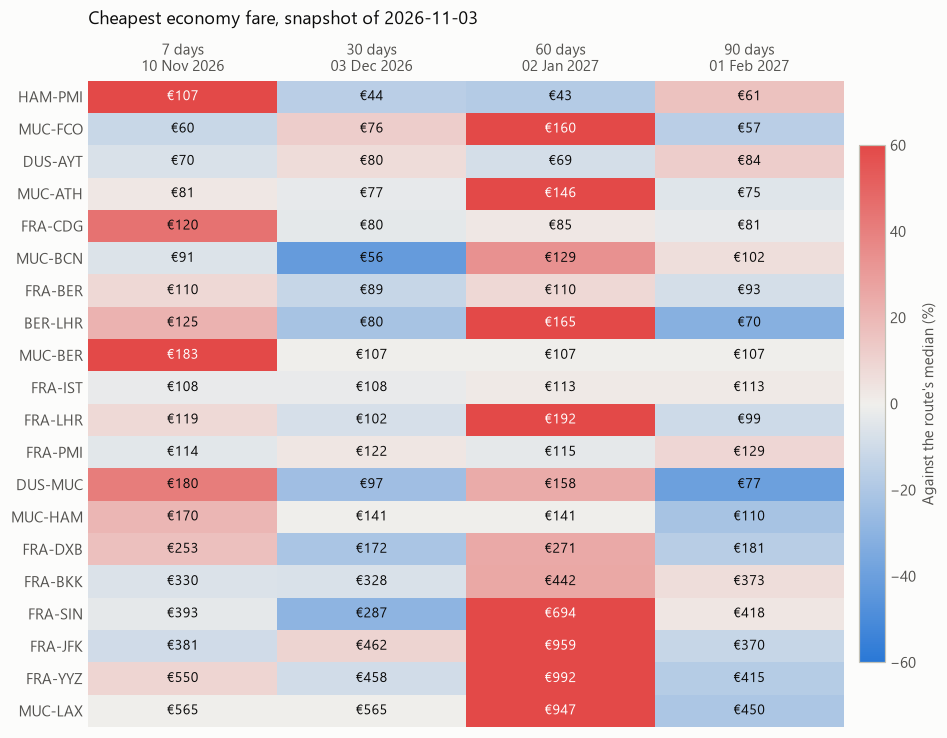

Routes whose dearest fare is the 60-day column: 60% (12 of 20)


In [20]:
grid = google.assign(route=google["origin"] + "-" + google["destination"]).pivot_table(index="route", columns="lead", values="price", aggfunc="min")
grid = grid.loc[grid.median(axis=1).sort_values().index]
relative_grid = grid.div(grid.median(axis=1), axis=0)
departure_by_lead = google.groupby("lead")["departure_date"].first()
fig, ax = plt.subplots(figsize=(8.5, 6.6))
image = ax.imshow(100 * (relative_grid - 1), cmap=DIVERGING, norm=TwoSlopeNorm(vcenter=0, vmin=-60, vmax=60), aspect="auto")
ax.set_xticks(range(grid.shape[1]), [f"{lead} days\n{departure_by_lead[lead]:%d %b %Y}" for lead in grid.columns])
ax.set_yticks(range(grid.shape[0]), grid.index)
ax.xaxis.tick_top()
ax.spines["bottom"].set_visible(False)
for y, row in enumerate(grid.to_numpy()):
    for x, value in enumerate(row):
        if np.isfinite(value):
            strong = abs(relative_grid.iloc[y, x] - 1) > .45
            ax.text(x, y, f"€{value:,.0f}", ha="center", va="center", fontsize=9, color="#ffffff" if strong else INK)
ax.grid(False)
ax.set_title(f"Cheapest economy fare, snapshot of {google['snapshot_date'].max().date()}", pad=12)
fig.colorbar(image, ax=ax, label="Against the route's median (%)", pad=0.02, shrink=.8)
plt.show()
share_high = (relative_grid.idxmax(axis=1) == 60).mean()
print(f"Routes whose dearest fare is the 60-day column: {share_high:.0%} ({(relative_grid.idxmax(axis=1) == 60).sum()} of {len(relative_grid)})")